# Task 1: Restaurant Rating Prediction
**Cognifyz Technologies - Machine Learning Internship**

**Goal:** predict a restaurant's *Aggregate rating* from its other features using regression.

**Approach in one paragraph.** Inspect the official dataset first, explore it, identify data problems (target leakage, unrated rows, mixed currencies), preprocess and engineer features *inside a scikit-learn Pipeline* so nothing leaks from test data, compare Linear Regression / Decision Tree / Random Forest, tune with cross-validation on the training set only, diagnose over/under-fitting, then explain which features matter and demonstrate predictions.

All reusable logic lives in `../src/` (config, data loading, feature engineering, modelling, plotting). This notebook calls it and explains every decision.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
%matplotlib inline

import visualize as viz           # also applies the seaborn theme
from config import *
from data_loader import load_data, prepare_data
from modeling import *
from features import FeatureEngineer
pd.set_option("display.max_columns", 30, "display.width", 160)
SAVE = lambda fig, name: fig.savefig(FIGURES_DIR / name, dpi=150, bbox_inches="tight")

## 1. Dataset understanding

In [2]:
df = load_data()
print("Shape:", df.shape)
df.head()

Shape: (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,1200,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",1500,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",1500,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   str    
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   str    
 4   Address               9551 non-null   str    
 5   Locality              9551 non-null   str    
 6   Locality Verbose      9551 non-null   str    
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   str    
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   str    
 12  Has Table booking     9551 non-null   str    
 13  Has Online delivery   9551 non-null   str    
 14  Is delivering now     9551 non-null   str    
 15  Switch to order menu  9551 non-n

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Restaurant ID,9551.0,9.051128e+06,8.791521e+06,53.000000,301962.500000,6.004089e+06,1.835229e+07,1.850065e+07
Country Code,9551.0,1.836562e+01,5.675055e+01,1.000000,1.000000,1.000000e+00,1.000000e+00,2.160000e+02
Longitude,9551.0,6.412657e+01,4.146706e+01,-157.948486,77.081343,7.719196e+01,7.728201e+01,1.748321e+02
Latitude,9551.0,2.585438e+01,1.100794e+01,-41.330428,28.478713,2.857047e+01,2.864276e+01,5.597698e+01
Average Cost for two,9551.0,1.199211e+03,1.612118e+04,0.000000,250.000000,4.000000e+02,7.000000e+02,8.000000e+05
Price range,9551.0,1.804837e+00,9.056088e-01,1.000000,1.000000,2.000000e+00,2.000000e+00,4.000000e+00
Aggregate rating,9551.0,2.666370e+00,1.516378e+00,0.000000,2.500000,3.200000e+00,3.700000e+00,4.900000e+00
Votes,9551.0,1.569097e+02,4.301691e+02,0.000000,5.000000,3.100000e+01,1.310000e+02,1.093400e+04


**Column dictionary (derived from inspecting the real file):**

| Column | Type | Meaning | Role |
|---|---|---|---|
| Restaurant ID | int | unique id | dropped (identifier) |
| Restaurant Name | text | name (7,446 unique) | dropped |
| Country Code | int | 15 countries (India = 1 is ~90%) | feature (categorical) |
| City | text | 141 cities | feature (categorical) |
| Address / Locality / Locality Verbose | text | location strings, very high cardinality | dropped (City + lat/long cover location) |
| Longitude, Latitude | float | coordinates | features |
| Cuisines | text | comma-separated, multi-valued | engineered features |
| Average Cost for two | int | cost **in local currency** | engineered (see below) |
| Currency | text | 12 distinct currencies | used to normalise cost |
| Has Table booking / Has Online delivery / Is delivering now | Yes/No | service flags | features |
| Switch to order menu | text | always "No" | dropped (constant) |
| Price range | int 1-4 | relative price tier | feature |
| **Aggregate rating** | float 0-4.9 | **TARGET** | target |
| Rating color / Rating text | text | label derived from the rating | **dropped: target leakage** |
| Votes | int | number of votes | feature |

## 2. Exploratory data analysis

### 2.1 Missing values and duplicates

In [5]:
miss = df.isna().sum()
print("Missing values:\n", miss[miss > 0].to_string())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate Restaurant IDs:", df["Restaurant ID"].duplicated().sum())
print("Constant columns:", [c for c in df.columns if df[c].nunique() == 1])

Missing values:
 Cuisines    9

Duplicate rows: 0
Duplicate Restaurant IDs: 0
Constant columns: ['Switch to order menu']


Only `Cuisines` has missing values (9 rows, <0.1%), so filling them with `'Unknown'` is safe. No duplicates exist, so nothing needs removing.

### 2.2 Distribution of the target

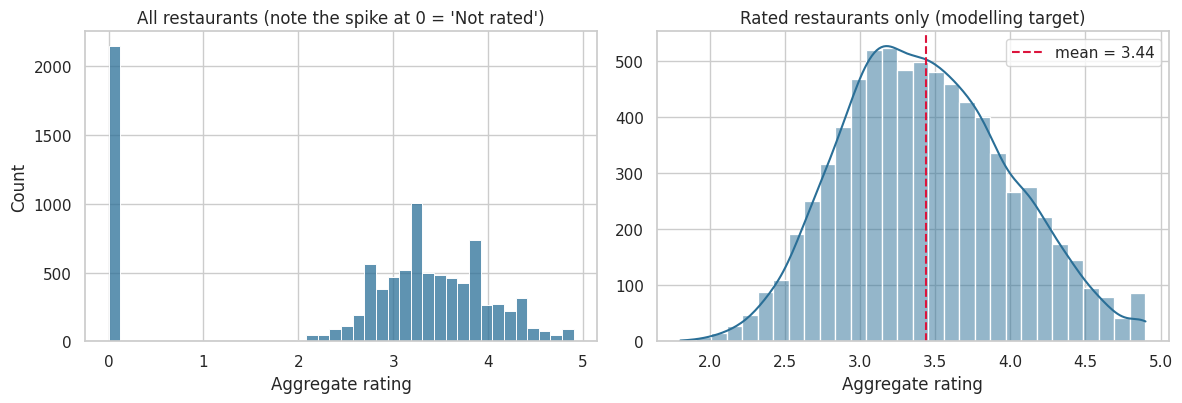

Zero ratings: 2148 of 9551 (22.5%)
Votes of the zero-rated restaurants: {'min': 0.0, '50%': 0.0, 'max': 3.0}
Rated only: mean=3.44, std=0.55, range 1.8-4.9


In [6]:
rated = df[df[TARGET] > 0]
fig = viz.plot_rating_distribution(df[TARGET], rated[TARGET], "eda_rating_distribution.png")
plt.show()
print(f"Zero ratings: {(df[TARGET]==0).sum()} of {len(df)} ({(df[TARGET]==0).mean():.1%})")
print("Votes of the zero-rated restaurants:", df.loc[df[TARGET]==0, "Votes"].describe()[["min","50%","max"]].to_dict())
print(f"Rated only: mean={rated[TARGET].mean():.2f}, std={rated[TARGET].std():.2f}, range {rated[TARGET].min()}-{rated[TARGET].max()}")

**Finding:** 2,148 restaurants (22.5%) have a rating of 0, and every one of them has 3 or fewer votes. A `0` here means *"Not rated yet"*, not *"terrible"*. Mixing these into a regression would force the model to learn two different things (is there a rating at all? + how good is it?). **Decision:** the main model trains on the 7,403 rated restaurants. I measure the effect of including the rest later (Section 7.4).

Among rated restaurants the distribution is roughly bell-shaped, centred near 3.4.

### 2.3 Target leakage check: `Rating color` and `Rating text`

In [7]:
print(df.groupby("Rating text")[TARGET].agg(["min", "max", "count"]))
print()
print(pd.crosstab(df["Rating color"], df["Rating text"]))

             min  max  count
Rating text                 
Average      2.5  3.4   3737
Excellent    4.5  4.9    301
Good         3.5  3.9   2100
Not rated    0.0  0.0   2148
Poor         1.8  2.4    186
Very Good    4.0  4.4   1079

Rating text   Average  Excellent  Good  Not rated  Poor  Very Good
Rating color                                                      
Dark Green          0        301     0          0     0          0
Green               0          0     0          0     0       1079
Orange           3737          0     0          0     0          0
Red                 0          0     0          0   186          0
White               0          0     0       2148     0          0
Yellow              0          0  2100          0     0          0


Each `Rating text` covers an exact, non-overlapping rating interval (e.g. *Excellent* = 4.5-4.9). They are just the target re-labelled, so using them would give the model the answer. **Both are dropped.**

### 2.4 Numerical features

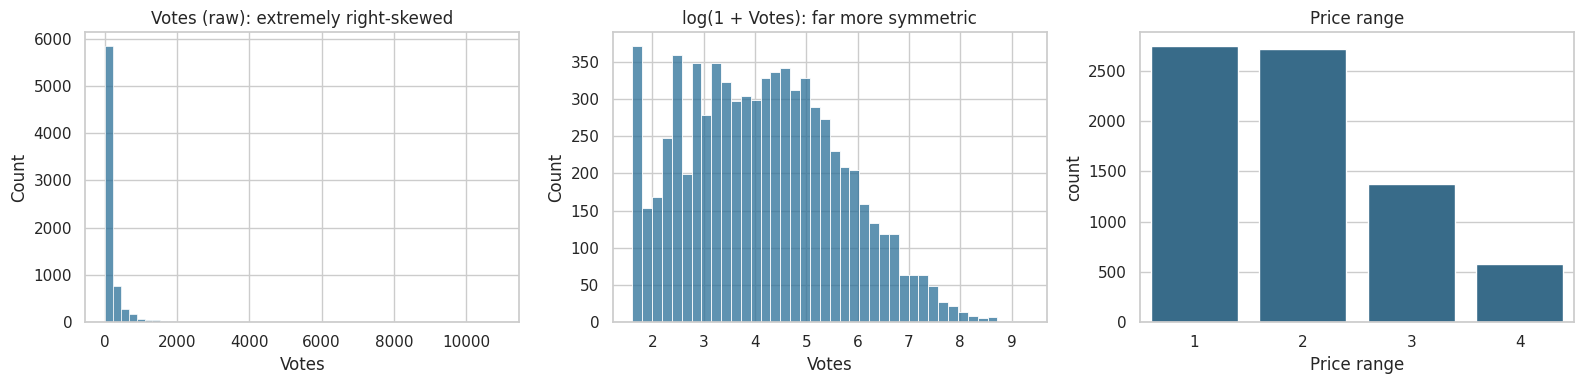

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(rated["Votes"], bins=50, ax=ax[0], color=viz.ACCENT).set(title="Votes (raw): extremely right-skewed")
sns.histplot(np.log1p(rated["Votes"]), bins=40, ax=ax[1], color=viz.ACCENT).set(title="log(1 + Votes): far more symmetric")
sns.countplot(x=rated["Price range"], ax=ax[2], color=viz.ACCENT).set(title="Price range")
plt.tight_layout(); SAVE(fig, "eda_numeric_distributions.png"); plt.show()

`Votes` ranges from 0 to ~10,900 with a long tail, so a `log1p` transform is justified (it also helps Linear Regression).

### 2.5 Cost is not comparable across countries

In [9]:
cost = df[df["Average Cost for two"] > 0]
print("Rows with cost = 0:", (df["Average Cost for two"] == 0).sum())
cost.groupby("Currency")["Average Cost for two"].agg(["count", "median", "max"]).sort_values("count", ascending=False)

Rows with cost = 0: 18


,count,median,max
Currency,,,
Indian Rupees(Rs.),8643,450.0,8000
Dollar($),473,25.0,500
Pounds(��),80,40.0,230
Brazilian Real(R$),60,100.0,400
Rand(R),60,340.0,3210
Emirati Diram(AED),60,145.0,500
NewZealand($),40,60.0,200
Turkish Lira(TL),34,70.0,400
Botswana Pula(P),22,1150.0,6000


The median 'cost for two' is 450 in Indian Rupees, 25 in Dollars and 200,000 in Indonesian Rupiah. A model treating these as one numeric scale would be misled. **Feature engineering fix:** divide cost by the median cost *of its own currency* (learned from the training set only) and take the log: a unit-free "how expensive for its market" feature.

### 2.6 Categorical features and relationships with the rating

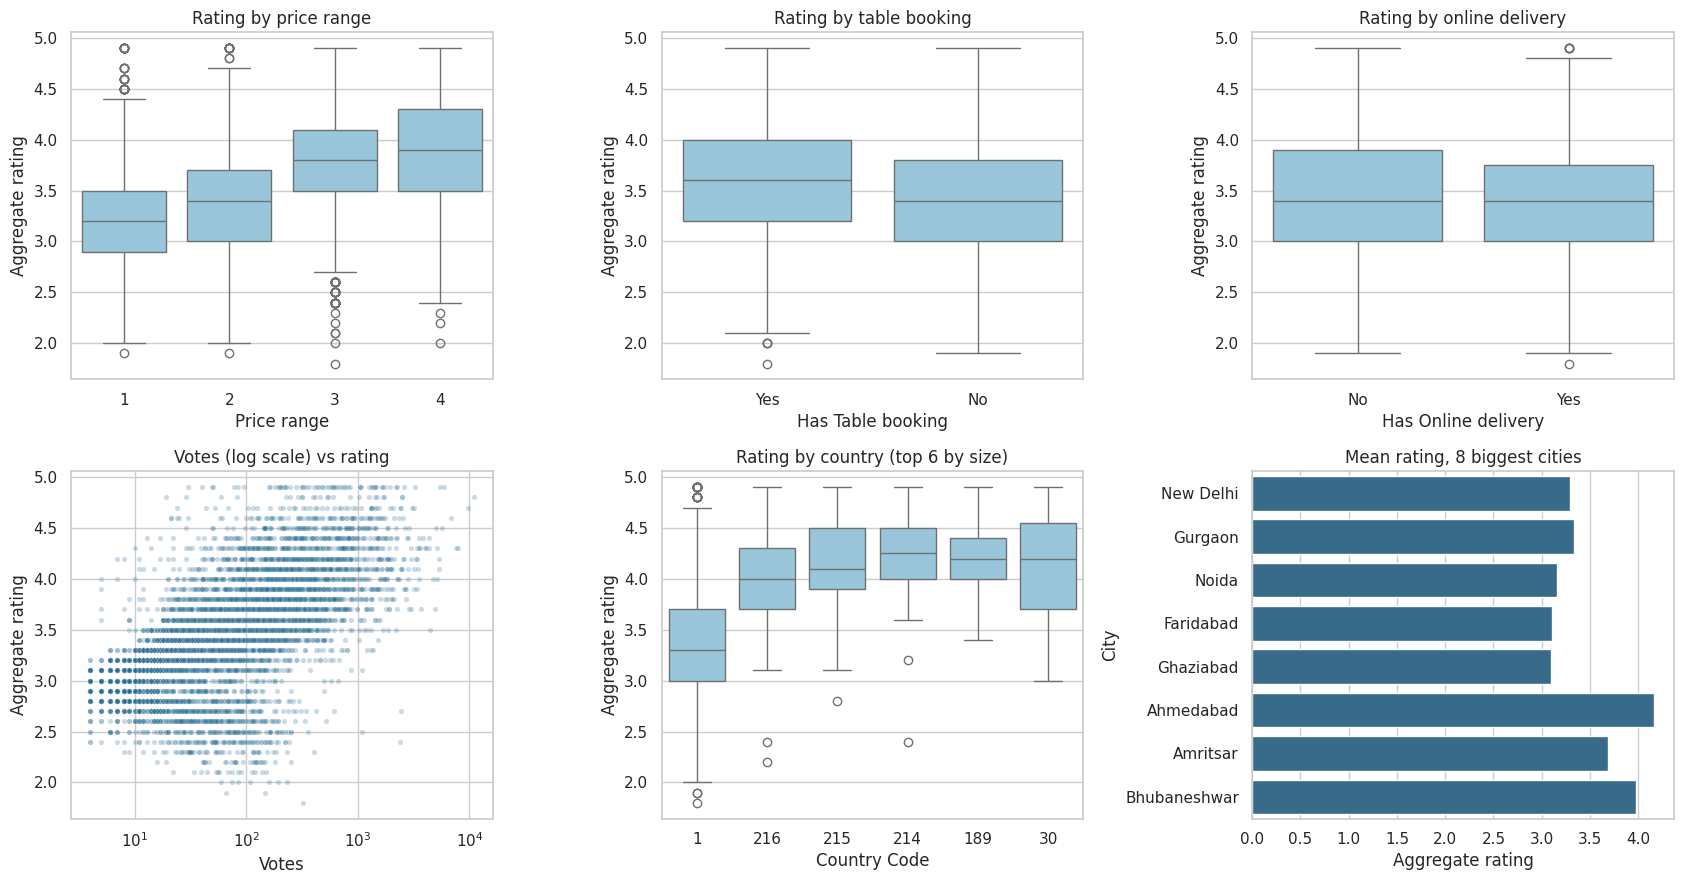

In [10]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
sns.boxplot(data=rated, x="Price range", y=TARGET, ax=ax[0,0], color="#8ecae6").set(title="Rating by price range")
sns.boxplot(data=rated, x="Has Table booking", y=TARGET, ax=ax[0,1], color="#8ecae6").set(title="Rating by table booking")
sns.boxplot(data=rated, x="Has Online delivery", y=TARGET, ax=ax[0,2], color="#8ecae6").set(title="Rating by online delivery")
sns.scatterplot(data=rated, x="Votes", y=TARGET, alpha=0.25, s=14, ax=ax[1,0], color=viz.ACCENT)
ax[1,0].set(xscale="log", title="Votes (log scale) vs rating")
top_c = rated["Country Code"].value_counts().index[:6]
sns.boxplot(data=rated[rated["Country Code"].isin(top_c)], x="Country Code", y=TARGET, order=top_c, ax=ax[1,1], color="#8ecae6").set(title="Rating by country (top 6 by size)")
top_city = rated["City"].value_counts().head(8).index
sns.barplot(data=rated[rated["City"].isin(top_city)], x=TARGET, y="City", order=top_city, ax=ax[1,2], color=viz.ACCENT, errorbar=None).set(title="Mean rating, 8 biggest cities")
plt.tight_layout(); SAVE(fig, "eda_relationships.png"); plt.show()

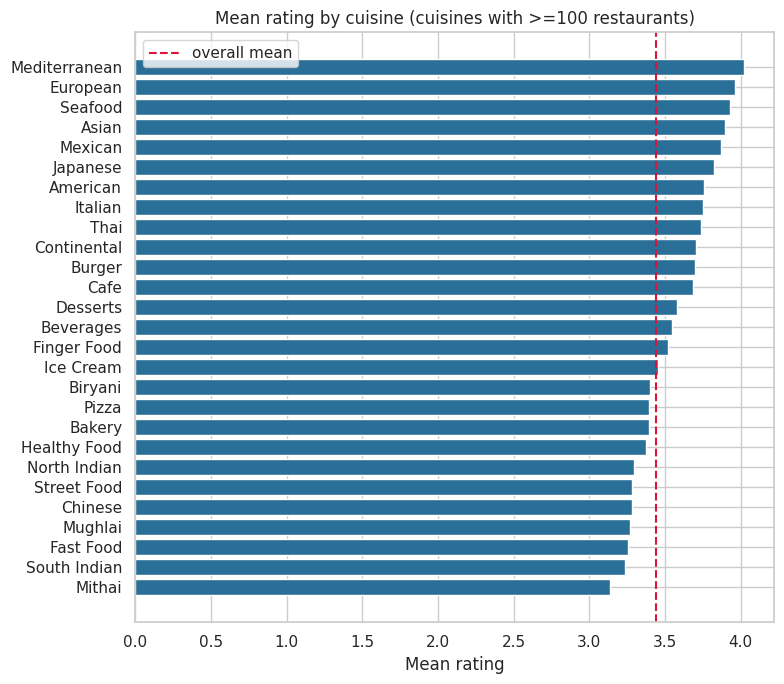

Distinct cuisines: 144 | avg cuisines per restaurant: 2.2


In [11]:
# Cuisines are multi-valued: explode, then average the rating of restaurants serving each one
cu = rated.assign(c=rated["Cuisines"].fillna("Unknown").str.split(",")).explode("c")
cu["c"] = cu["c"].str.strip()
stats = cu.groupby("c")[TARGET].agg(["count", "mean"])
top = stats[stats["count"] >= 100].sort_values("mean")
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top.index, top["mean"], color=viz.ACCENT)
ax.axvline(rated[TARGET].mean(), color="crimson", ls="--", label="overall mean")
ax.set(title="Mean rating by cuisine (cuisines with >=100 restaurants)", xlabel="Mean rating"); ax.legend()
plt.tight_layout(); SAVE(fig, "eda_cuisines.png"); plt.show()
print("Distinct cuisines:", cu["c"].nunique(), "| avg cuisines per restaurant:", round(rated['Cuisines'].fillna('').str.count(',').add(1).mean(), 2))

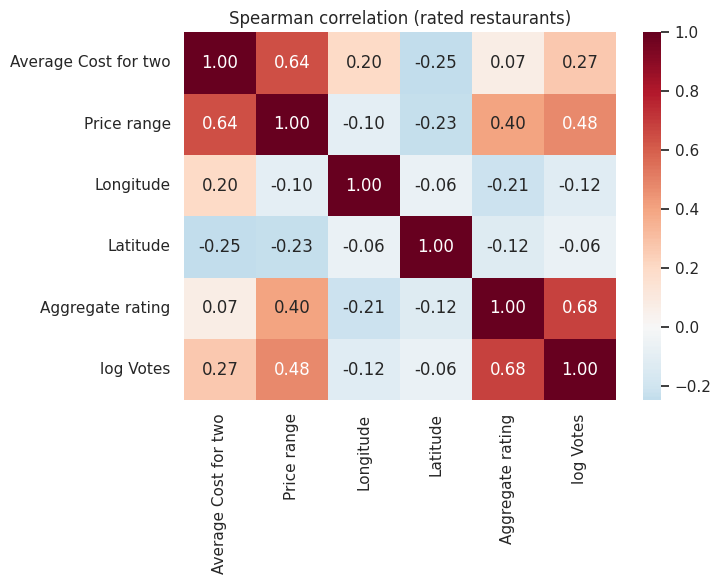

In [12]:
num = rated[["Votes", "Average Cost for two", "Price range", "Longitude", "Latitude", TARGET]].copy()
num["log Votes"] = np.log1p(num["Votes"])
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(num.drop(columns="Votes").corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Spearman correlation (rated restaurants)")
plt.tight_layout(); SAVE(fig, "eda_correlation.png"); plt.show()

**EDA takeaways**
* `Votes` is the strongest single signal (Spearman correlation about 0.85 with the rating across all restaurants; clear upward trend in the scatter plot).
* `Price range` has a clear positive relationship: median rating rises from about 3.2 (range 1) to about 3.9 (range 4).
* Table booking shows a modest gain (median about 3.6 vs 3.4); online delivery shows almost no difference.
* Countries differ strongly: India (code 1, ~90% of rows) has noticeably lower ratings (median about 3.3) than the other countries (medians about 4.0 and above), so country/city is informative, though confounded with the data being India-heavy.
* Rating also varies across cuisines (see cuisine chart), so cuisine features are worth keeping.
* Raw `Average Cost for two` is a weak, currency-polluted signal, hence the engineered replacement.

## 3. Data preprocessing
Decisions (all implemented in `src/data_loader.py` and the pipeline):

| Issue | Decision | Why |
|---|---|---|
| 9 missing `Cuisines` | fill with `'Unknown'` | tiny share; keeps the rows |
| Duplicates | none found; `drop_duplicates()` kept as a safeguard | |
| Rating = 0 ("Not rated") | exclude from main model | 0 means "no rating exists", not a low rating |
| `Rating color/text` | drop | target leakage |
| IDs, name, address, locality | drop | identifiers / very high cardinality |
| `Switch to order menu` | drop | constant |
| Categorical (`Country Code`, `City`) | One-Hot, rare categories (<20 rows) grouped, unseen = ignored | stops 141 cities exploding the feature space |
| Numeric | StandardScaler | needed by Linear Regression, harmless for trees |

In [13]:
pd.Series(DROPPED_COLUMNS, name="reason").to_frame()

,reason
Rating color,LEAKAGE - deterministic bin of the target
Rating text,LEAKAGE - deterministic bin of the target
Restaurant ID,"identifier, carries no signal"
Restaurant Name,identifier-like free text (7446 unique names)
Address,"free text, ~8900 unique values"
Locality,very high cardinality (1208); City + lat/long ...
Locality Verbose,very high cardinality (1265); duplicates Locality
Switch to order menu,constant column (only 'No')


In [14]:
X, y = prepare_data(df)
print("Modelling set:", X.shape, "| target range:", y.min(), "-", y.max())

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Modelling set: (7403, 12) | target range: 1.8 - 4.9
Train: (5922, 12) | Test: (1481, 12)


**Split first, then fit everything.** The 80/20 split happens *before* any encoder, scaler or feature statistic is fitted. Those are all inside a `Pipeline`, so they only ever learn from training rows (and from the training fold only during cross-validation).

## 4. Feature engineering
Implemented in `src/features.py` as a `FeatureEngineer` transformer. Anything it *learns* (top cuisines, median cost per currency) is learned in `fit()` on training data only.

| Feature | Why |
|---|---|
| `votes_log` | tames the heavy right skew of Votes |
| `cost_ratio_log` | currency-normalised price level (cost / median of own currency, logged) |
| `num_cuisines` | menu breadth |
| `cuisine_<top 15>` | 0/1 flags: Cuisines is multi-valued, so ordinary one-hot would be wrong |
| Yes/No flags to 0/1 | model-readable |
| `Latitude`, `Longitude`, `Country Code`, `City`, `price_range` | location and price tier |

I deliberately did **not** add features I could not justify from the EDA (e.g. text from names or addresses).

In [15]:
fe = FeatureEngineer().fit(X_train)
print("Top cuisines learned from TRAIN only:", fe.top_cuisines_)
fe.transform(X_train).head()

Top cuisines learned from TRAIN only: ['North Indian', 'Chinese', 'Fast Food', 'Mughlai', 'Italian', 'Continental', 'Cafe', 'Bakery', 'Desserts', 'South Indian', 'Street Food', 'American', 'Pizza', 'Burger', 'Mithai']


,votes_log,cost_ratio_log,price_range,num_cuisines,cuisine_North Indian,cuisine_Chinese,cuisine_Fast Food,cuisine_Mughlai,cuisine_Italian,cuisine_Continental,cuisine_Cafe,cuisine_Bakery,cuisine_Desserts,cuisine_South Indian,cuisine_Street Food,cuisine_American,cuisine_Pizza,cuisine_Burger,cuisine_Mithai,Has Table booking,Has Online delivery,Is delivering now,Latitude,Longitude,Country Code,City
210,4.983607,0.470004,3,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,34.759551,-84.992342,216,Dalton
2487,2.995732,-1.609438,1,2,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,28.655697,77.229983,1,New Delhi
6309,4.521789,0.262364,2,2,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,28.567240,77.320519,1,Noida
110,6.142037,0.470004,3,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,33.958400,-83.407500,216,Athens
51,2.708050,-0.105361,3,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,-22.966647,-43.219563,30,Rio de Janeiro


## 5. Model building
Four models in an identical pipeline (`FeatureEngineer -> encode/scale -> model`):

* **Baseline (always predict the training mean)**: not required, but it tells us what "no skill" looks like (R² = 0). Any real model must beat this.
* **Linear Regression**: simple, interpretable benchmark.
* **Decision Tree**: captures non-linear rules; prone to overfitting if unconstrained.
* **Random Forest**: averages many decorrelated trees; usually strong on tabular data.

In [16]:
base_table, base_models = compare_models(X_train, y_train, X_test, y_test)
base_table.round(3)

,train_MAE,train_MSE,train_RMSE,train_R2,test_MAE,test_MSE,test_RMSE,test_R2,cv_RMSE,cv_RMSE_std
Model,,,,,,,,,,
Baseline (mean),0.448,0.304,0.551,0.000,0.455,0.309,0.556,-0.000,0.551,0.014
Linear Regression,0.264,0.127,0.356,0.582,0.261,0.121,0.348,0.608,0.359,0.018
Decision Tree,0.000,0.000,0.000,1.000,0.348,0.228,0.478,0.263,0.480,0.005
Random Forest,0.094,0.017,0.129,0.945,0.243,0.108,0.329,0.649,0.350,0.015


## 6. Model evaluation
Metrics (all on the held-out test set, with train and 5-fold CV alongside to expose overfitting):
* **MAE**: average absolute error, in rating points (easy to explain).
* **MSE**: average squared error; penalises large mistakes.
* **RMSE** = sqrt(MSE): same units as the rating.
* **R²**: share of rating variance explained (0 = no better than predicting the mean).

In [17]:
cols = ["test_MAE", "test_MSE", "test_RMSE", "test_R2"]
base_table[cols].round(4)

,test_MAE,test_MSE,test_RMSE,test_R2
Model,,,,
Baseline (mean),0.4552,0.3093,0.5561,-0.0001
Linear Regression,0.2613,0.1212,0.3482,0.6080
Decision Tree,0.3479,0.2281,0.4776,0.2626
Random Forest,0.2431,0.1085,0.3294,0.6492


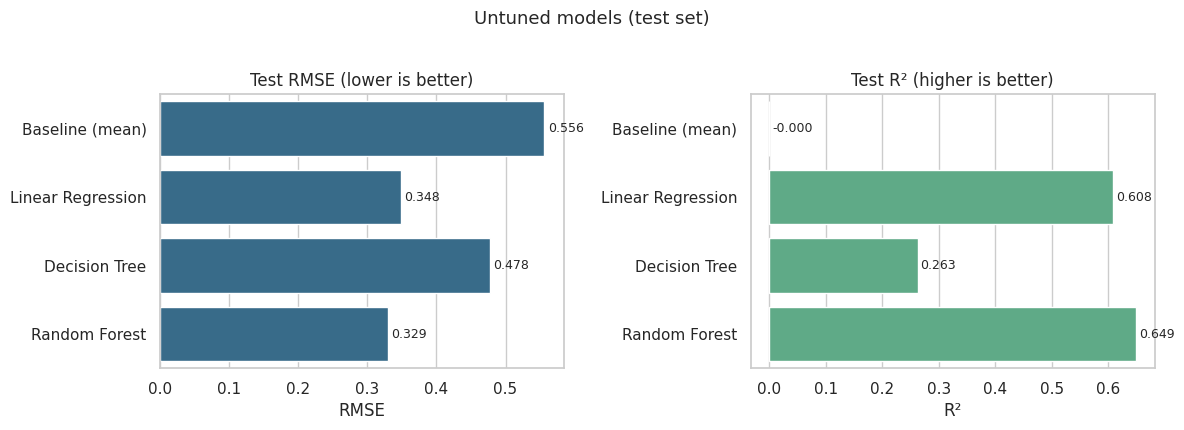

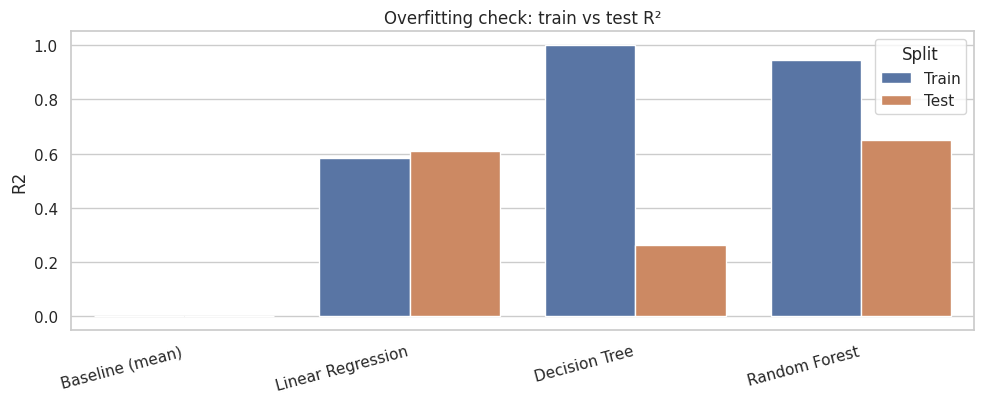

In [18]:
viz.plot_model_comparison(base_table, "Untuned models (test set)", "model_comparison_untuned.png"); plt.show()
viz.plot_overfit_check(base_table, "overfitting_check_untuned.png"); plt.show()

**Reading the results**
* The untuned **Decision Tree memorises the training data** (train R² = 1.00) but generalises poorly (test R² ~0.26): a textbook case of **overfitting**.
* **Linear Regression** is stable (train and test close) - it's limited by being linear, but not overfit.
* The **Random Forest is the best of the three** on the test set, but still shows a big train/test gap - there is room to regularise it.

## 7. Model improvement
### 7.1 Hyper-parameter tuning
Tuning uses **cross-validation inside the training set only** (the test set is not touched):
* Decision Tree: `GridSearchCV` over `max_depth` and `min_samples_leaf` (both limit tree complexity).
* Random Forest: `RandomizedSearchCV` (12 sampled combinations) over `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features`.

*(This cell takes a few minutes on a laptop CPU.)*

In [19]:
dt_search = tune_decision_tree(X_train, y_train)
rf_search = tune_random_forest(X_train, y_train)
print("Best Decision Tree params:", dt_search.best_params_)
print("Best Random Forest params:", rf_search.best_params_)

Best Decision Tree params: {'model__max_depth': 8, 'model__min_samples_leaf': 40}
Best Random Forest params: {'model__n_estimators': 300, 'model__min_samples_leaf': 3, 'model__max_features': 0.3, 'model__max_depth': 20}


In [20]:
tuned = {"Linear Regression": base_models["Linear Regression"],
         "Decision Tree (tuned)": dt_search.best_estimator_,
         "Random Forest (tuned)": rf_search.best_estimator_}
tuned_table = pd.DataFrame([{"Model": n, **evaluate(m, X_train, y_train, X_test, y_test)} for n, m in tuned.items()]).set_index("Model")
tuned_table.round(3)

,train_MAE,train_MSE,train_RMSE,train_R2,test_MAE,test_MSE,test_RMSE,test_R2,cv_RMSE,cv_RMSE_std
Model,,,,,,,,,,
Linear Regression,0.264,0.127,0.356,0.582,0.261,0.121,0.348,0.608,0.359,0.018
Decision Tree (tuned),0.262,0.126,0.355,0.585,0.270,0.132,0.363,0.574,0.374,0.016
Random Forest (tuned),0.173,0.057,0.239,0.813,0.239,0.105,0.323,0.662,0.342,0.015


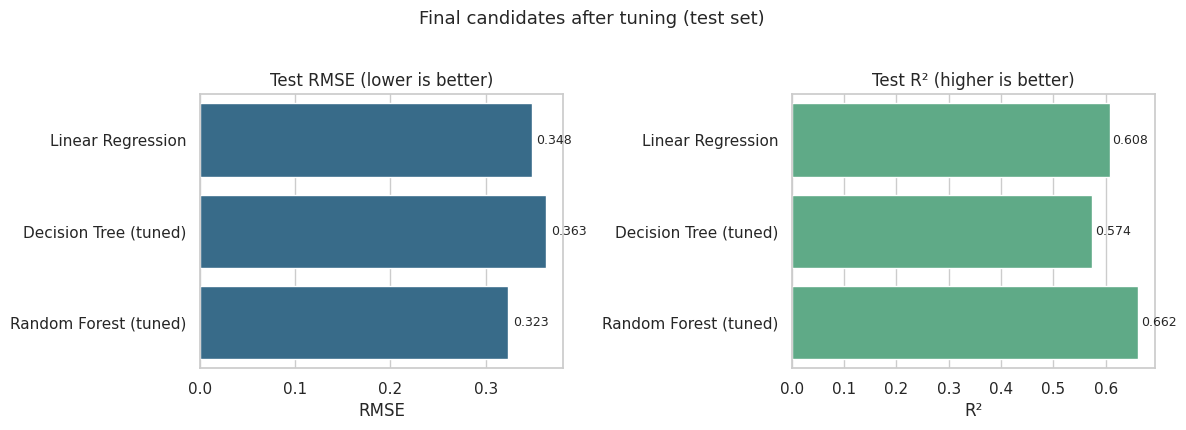

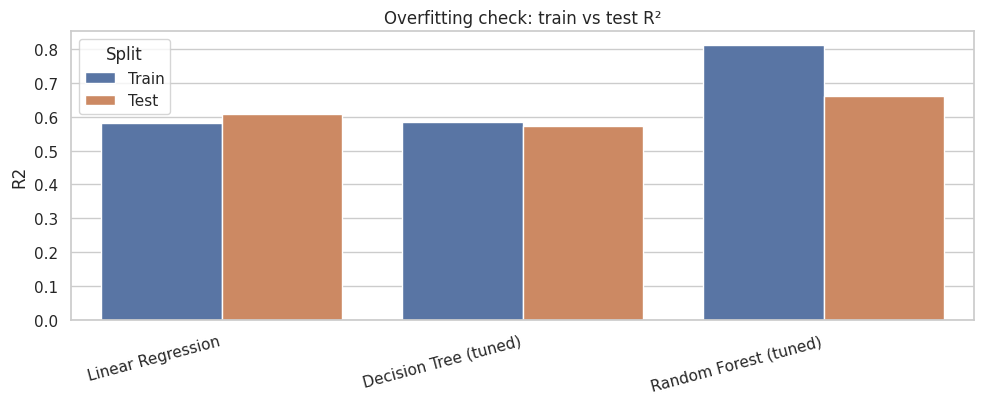

In [21]:
viz.plot_model_comparison(tuned_table, "Final candidates after tuning (test set)", "model_comparison_tuned.png"); plt.show()
viz.plot_overfit_check(tuned_table, "overfitting_check_tuned.png"); plt.show()

In [22]:
best_name = tuned_table["cv_RMSE"].idxmin()      # chosen by CV on train, NOT by test score
best = tuned[best_name]
print("Selected model:", best_name)
pred = best.predict(X_test)
final = regression_metrics(y_test, pred)
print({k: round(v, 4) for k, v in final.items()})

Selected model: Random Forest (tuned)
{'MAE': 0.2393, 'MSE': 0.1046, 'RMSE': 0.3234, 'R2': 0.6618}


### 7.2 Over/under-fitting diagnosis
* **Tuning fixed the Decision Tree's overfitting** (train/test gap vanished), but at the cost of becoming a simple model whose test R² is *below* Linear Regression: under tuning it behaves like a high-bias model.
* The tuned **Random Forest has train R² ~0.81 vs test ~0.66**. A gap remains (forests always fit training data better), but test error is the lowest of all models and CV RMSE agrees (it's not a lucky split), so we accept it.
* The learning curve below shows a persistent gap between training RMSE (about 0.24) and cross-validated RMSE (about 0.345), with the CV error still falling slowly as training size grows. So the forest has some variance and more data would probably help a little, but the curve is flattening and the model is not badly overfit.

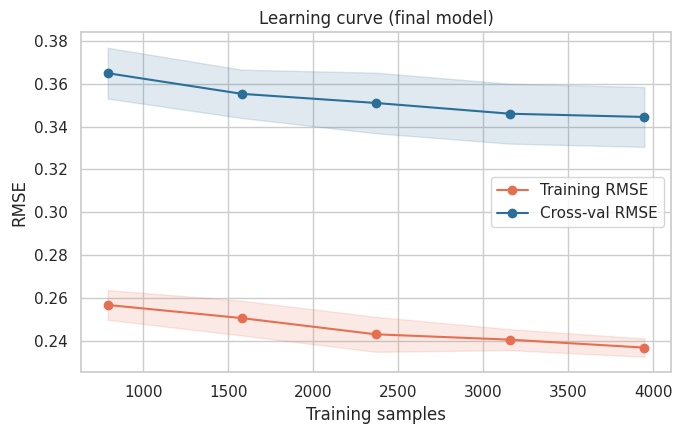

In [23]:
viz.plot_learning_curve(best, X_train, y_train, "learning_curve.png"); plt.show()

### 7.3 Residual analysis
Residuals should be centred on 0 with no strong pattern vs the prediction. (The diagonal stripes appear because true ratings come in 0.1 steps.)

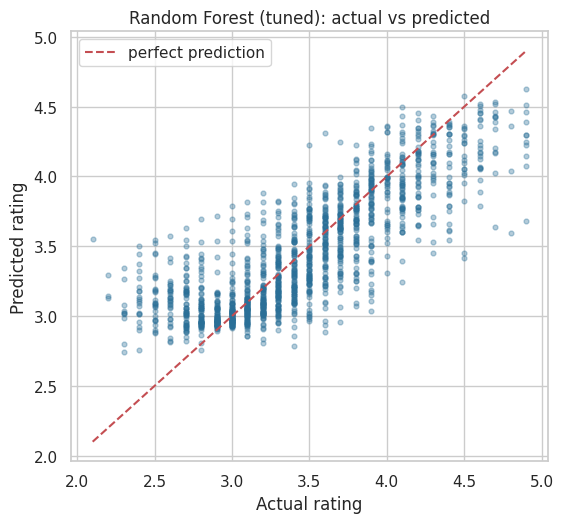

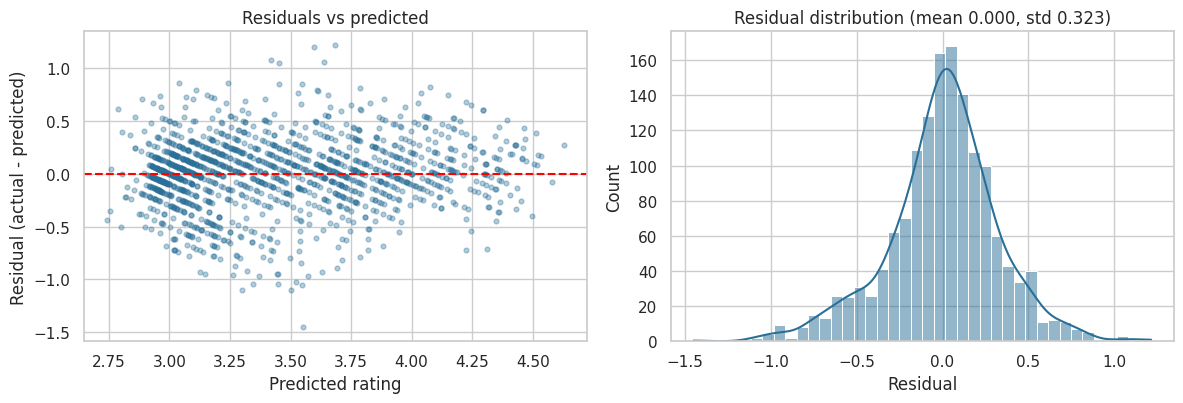

In [24]:
viz.plot_actual_vs_predicted(y_test, pred, f"{best_name}: actual vs predicted", "actual_vs_predicted.png"); plt.show()
viz.plot_residuals(y_test, pred, "residuals.png"); plt.show()

### 7.4 Robustness experiments (ablations)
Two questions an examiner is likely to ask:
1. *How much does the model depend on `Votes`?*
2. *What if we include the "Not rated" (0) restaurants?*

Each row uses its **own** train/test split, so rows are not strictly comparable with each other in absolute terms. They show the direction of the effect.

In [25]:
rf_params = {k.replace("model__", ""): v for k, v in rf_search.best_params_.items()}
from sklearn.ensemble import RandomForestRegressor
def rf_score(Xa, ya, label, mutate=None):
    a_tr, a_te, b_tr, b_te = train_test_split(Xa, ya, test_size=TEST_SIZE, random_state=RANDOM_STATE)
    if mutate: a_tr, a_te = mutate(a_tr), mutate(a_te)
    m = build_pipeline(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **rf_params)).fit(a_tr, b_tr)
    return {"Experiment": label, "n_rows": len(Xa), **regression_metrics(b_te, m.predict(a_te))}
Xall, yall = prepare_data(df, drop_unrated=False)
ablation = pd.DataFrame([
    rf_score(X, y, "Main: rated restaurants, all features"),
    rf_score(X, y, "Rated restaurants, WITHOUT Votes", lambda d: d.assign(Votes=0)),
    rf_score(Xall, yall, "Including 'Not rated' (rating 0) rows")]).set_index("Experiment")
ablation.round(3)

,n_rows,MAE,MSE,RMSE,R2
Experiment,,,,,
"Main: rated restaurants, all features",7403,0.239,0.105,0.323,0.662
"Rated restaurants, WITHOUT Votes",7403,0.294,0.141,0.376,0.543
Including 'Not rated' (rating 0) rows,9551,0.198,0.088,0.296,0.961


* **Without `Votes`, R² drops to ~0.54**, so Votes carries a lot of the signal, but the model still explains over half the variance from cuisine, location, price and service features. (Caveat: votes accumulate *with* ratings, so Votes is partly an outcome of popularity - fine for "predict from available features", but worth stating.)
* **Including unrated rows inflates R² to ~0.96**, but that is misleading: the model simply learns "very few votes -> rating 0", an almost trivial rule, and the zero-vs-rest gap dominates the variance. It does *not* mean we predict ratings better, which is why the main model excludes them.

## 8. Feature importance
Two complementary views:
* **Permutation importance** (model-agnostic, on test data, on the *raw* columns): how much RMSE increases when one column is shuffled. This is the more trustworthy of the two.
* **Random Forest built-in importance** (on engineered features): fast but biased towards high-cardinality / continuous features.

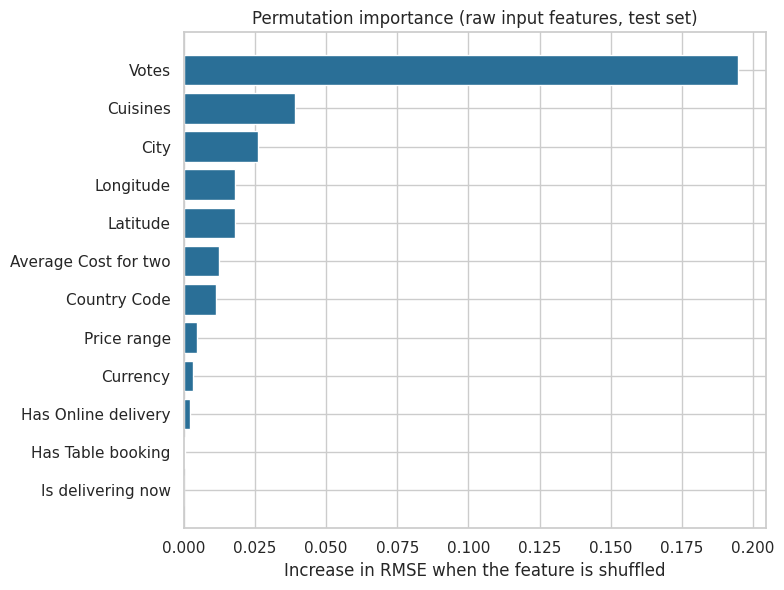

Votes                   0.1948
Cuisines                0.0392
City                    0.0262
Longitude               0.0181
Latitude                0.0178
Average Cost for two    0.0125
Country Code            0.0113
Price range             0.0046
Currency                0.0032
Has Online delivery     0.0022
Has Table booking       0.0006
Is delivering now       0.0000
dtype: float64

In [26]:
from sklearn.inspection import permutation_importance
perm = permutation_importance(best, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE,
                              scoring="neg_root_mean_squared_error", n_jobs=1)
perm_s = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
viz.plot_importance(perm_s, "Permutation importance (raw input features, test set)",
                    "Increase in RMSE when the feature is shuffled", name="permutation_importance.png"); plt.show()
perm_s.round(4)

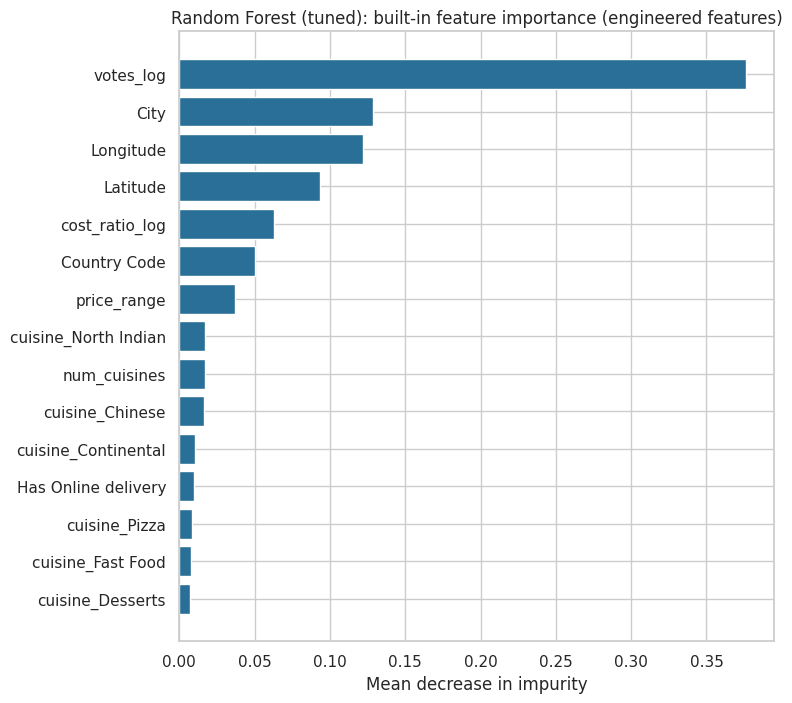

votes_log               0.3760
City                    0.1288
Longitude               0.1218
Latitude                0.0934
cost_ratio_log          0.0627
Country Code            0.0504
price_range             0.0372
cuisine_North Indian    0.0171
num_cuisines            0.0170
cuisine_Chinese         0.0162
dtype: float64

In [27]:
import sys; sys.path.insert(0, "../src")
from train import grouped_impurity_importance
imp = grouped_impurity_importance(best)
viz.plot_importance(imp, f"{best_name}: built-in feature importance (engineered features)",
                    "Mean decrease in impurity", name="feature_importance.png"); plt.show()
imp.head(10).round(4)

**Interpretation:** `Votes` dominates both rankings. Cuisines, city/location (city, latitude, longitude) and the price level come next; service flags (table booking, online delivery, delivering now) contribute very little. In practice: *how many people have rated a place, what it serves and where it is*, tell us most about its rating.

## 9. Predictions

### 9.1 Sample restaurants from the unseen test set

In [28]:
sample = X_test.sample(8, random_state=RANDOM_STATE)
demo = sample[["City", "Cuisines", "Price range", "Votes"]].copy()
demo["Actual"] = y_test.loc[sample.index].values
demo["Predicted"] = np.clip(best.predict(sample), 0, 5).round(2)
demo["Abs error"] = (demo["Actual"] - demo["Predicted"]).abs().round(2)
demo

,City,Cuisines,Price range,Votes,Actual,Predicted,Abs error
1410,Gurgaon,"North Indian, Continental, Mughlai, Asian",4,2806,4.1,3.93,0.17
6792,Noida,"North Indian, Chinese",2,23,2.3,2.99,0.69
1509,Gurgaon,"Bakery, Desserts",3,26,3.2,3.51,0.31
2970,New Delhi,North Indian,1,8,2.9,3.07,0.17
5434,New Delhi,Chinese,1,63,3.4,3.13,0.27
5586,New Delhi,"Cafe, North Indian, Continental, Chinese",2,142,3.9,3.56,0.34
2515,New Delhi,"North Indian, Mughlai, Chinese",2,4,3.0,3.00,0.00
4700,New Delhi,"North Indian, Chinese, Street Food",1,34,3.5,3.20,0.30


### 9.2 Predict for a custom restaurant

In [29]:
import predict as P
new_restaurant = {
    "Country Code": 1, "City": "New Delhi", "Longitude": 77.2, "Latitude": 28.6,
    "Cuisines": "North Indian, Chinese", "Average Cost for two": 800,
    "Currency": "Indian Rupees(Rs.)", "Has Table booking": "Yes",
    "Has Online delivery": "Yes", "Is delivering now": "No",
    "Price range": 2, "Votes": 250,
}
print(f"Predicted aggregate rating: {P.predict_rating(best, new_restaurant):.2f} / 5")

Predicted aggregate rating: 3.53 / 5


From a terminal you can do the same interactively with `python src/predict.py --interactive`.

## 10. Save the model
The saved object is the **entire pipeline**, so it accepts raw restaurant columns - no separate preprocessing code is needed at prediction time.

In [30]:
import joblib
joblib.dump(best, MODEL_PATH)
print("Saved:", MODEL_PATH)

Saved: /home/claude/Cognifyz-ML-Internship/Task-1-Restaurant-Rating-Prediction/models/best_model.joblib


## 11. Conclusions and limitations
* The tuned **Random Forest** is the best model by cross-validation and on the test set (see tables above for the exact numbers: typical error of roughly a quarter of a rating point, R² about two-thirds).
* The task is genuinely hard: restaurant quality is subjective and the dataset has no review text, so a ceiling well below R² = 1 is expected.
* **Leakage was the main trap** (`Rating color` / `Rating text`); handled by dropping them and putting all learning inside a Pipeline.
* **Limitations:** ~90% of rows are from India; `Votes` partly reflects popularity *after* ratings accumulate; unrated restaurants are excluded by design; results may not transfer to other countries.
* **Future work:** try gradient boosting (e.g. `HistGradientBoostingRegressor`), add review-text features if available, and evaluate per-country performance.